## Import libraries and set a reproducible random seed

In [41]:
import sqlite3
import numpy as np
import pandas as pd
import random
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## Generate synthetic customers and products

In [42]:
N_CUSTOMERS = 5000
N_PRODUCTS = 250
N_ORDERS = 12000

regions = ["North", "South", "East", "West", "Central"]
loyalty_tiers = ["Bronze", "Silver", "Gold", "Platinum"]  # ordinal
categories = ["Electronics", "Home", "Clothing", "Beauty", "Sports", "Books"]
brands = ["Nova", "Vertex", "Aster", "Pioneer", "UrbanCo", "Bright"]
payment_methods = ["Card", "PayPal", "Bank transfer", "Digital wallet"]
order_statuses = ["Delivered", "Processing", "Cancelled", "Returned"]

customers = pd.DataFrame({
    "customer_id": np.arange(1, N_CUSTOMERS + 1),
    "region": np.random.choice(regions, N_CUSTOMERS, p=[.22,.20,.18,.20,.20]),
    "loyalty_tier": np.random.choice(loyalty_tiers, N_CUSTOMERS, p=[.40,.30,.20,.10]),
    "signup_date": [
        (datetime(2021,1,1) + timedelta(days=int(x))).date().isoformat()
        for x in np.random.randint(0, 1700, N_CUSTOMERS)
    ],
    "age": np.random.randint(18, 76, N_CUSTOMERS)
})

products = pd.DataFrame({
    "product_id": np.arange(1, N_PRODUCTS + 1),
    "product_name": [f"Product_{i:03d}" for i in range(1, N_PRODUCTS + 1)],
    "category": np.random.choice(categories, N_PRODUCTS),
    "brand": np.random.choice(brands, N_PRODUCTS),
    "unit_price": np.round(np.random.lognormal(mean=3.1, sigma=.65, size=N_PRODUCTS), 2)
})
display(customers.head())
display(products.head())

,customer_id,region,loyalty_tier,signup_date,age
0,1,South,Bronze,2024-04-21,18
1,2,Central,Silver,2023-05-14,55
2,3,West,Gold,2022-07-02,56
3,4,East,Bronze,2023-11-27,66
4,5,North,Gold,2023-10-05,26


,product_id,product_name,category,brand,unit_price
0,1,Product_001,Home,Aster,17.90
1,2,Product_002,Home,Vertex,5.94
2,3,Product_003,Electronics,Bright,17.88
3,4,Product_004,Clothing,Vertex,10.75
4,5,Product_005,Beauty,Bright,14.09


## Generate orders and order items

In [43]:
order_dates = [
    (datetime(2024,1,1) + timedelta(days=int(x))).date().isoformat()
    for x in np.random.randint(0, 730, N_ORDERS)
]
order_customer_ids = np.random.randint(1, N_CUSTOMERS + 1, N_ORDERS)

orders = pd.DataFrame({
    "order_id": np.arange(1, N_ORDERS + 1),
    "customer_id": order_customer_ids,
    "order_date": order_dates,
    "payment_method": np.random.choice(payment_methods, N_ORDERS),
    "order_status": np.random.choice(order_statuses, N_ORDERS, p=[.78,.12,.06,.04]),
    "priority_level": np.random.choice(["Low", "Normal", "High"], N_ORDERS, p=[.20,.65,.15]),
    # Celsius is an interval scale: 0°C does not mean absence of temperature.
    "temperature_c": np.round(np.random.normal(15, 8, N_ORDERS), 1),
    "delivery_days": np.random.choice([1,2,3,4,5,6,7], N_ORDERS, p=[.08,.18,.25,.22,.14,.08,.05])
})

item_records = []
item_id = 1
price_lookup = products.set_index("product_id")["unit_price"].to_dict()
for oid in orders["order_id"]:
    n_items = int(np.random.choice([1,2,3,4,5], p=[.25,.32,.23,.14,.06]))
    chosen = np.random.choice(np.arange(1, N_PRODUCTS+1), size=n_items, replace=False)
    for pid in chosen:
        qty = int(np.random.choice([1,2,3,4], p=[.70,.20,.08,.02]))
        discount = float(np.random.choice([0,5,10,15,20], p=[.50,.20,.18,.08,.04]))
        item_records.append((int(oid), int(pid), qty, discount))
order_items = pd.DataFrame(item_records, columns=[
    "order_id", "product_id", "quantity", "discount_pct"
])
order_items["line_total"] = (
    order_items["quantity"] *
    order_items["product_id"].map(price_lookup) *
    (1 - order_items["discount_pct"]/100)
).round(2)

print("Customers:", len(customers))
print("Products:", len(products))
print("Orders:", len(orders))
print("Order items:", len(order_items))
display(orders.head())
display(order_items.head())

Customers: 5000
Products: 250
Orders: 12000
Order items: 29340


,order_id,customer_id,order_date,payment_method,order_status,priority_level,temperature_c,delivery_days
0,1,3961,2024-07-28,Card,Delivered,High,13.2,5
1,2,742,2024-05-29,Digital wallet,Delivered,Low,15.0,2
2,3,592,2024-01-31,Digital wallet,Delivered,Normal,18.9,1
3,4,750,2025-09-03,Digital wallet,Returned,Normal,18.9,3
4,5,2220,2024-10-28,Digital wallet,Processing,Normal,13.1,4


,order_id,product_id,quantity,discount_pct,line_total
0,1,106,2,15.0,116.98
1,2,194,3,10.0,114.88
2,2,4,2,15.0,18.27
3,3,32,2,0.0,37.68
4,4,127,2,5.0,50.41


## Create SQLite database with keys and constraints

In [44]:
DB_FILE = "synthetic_ecommerce.db"
conn = sqlite3.connect(DB_FILE)
conn.execute("PRAGMA foreign_keys = ON")

conn.executescript("""
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;

CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    region TEXT NOT NULL CHECK(region IN ('North','South','East','West','Central')),
    loyalty_tier TEXT NOT NULL CHECK(loyalty_tier IN ('Bronze','Silver','Gold','Platinum')),
    signup_date TEXT NOT NULL,
    age INTEGER NOT NULL CHECK(age BETWEEN 18 AND 100)
);

CREATE TABLE products (
    product_id INTEGER PRIMARY KEY,
    product_name TEXT NOT NULL UNIQUE,
    category TEXT NOT NULL,
    brand TEXT NOT NULL,
    unit_price REAL NOT NULL CHECK(unit_price > 0)
);

CREATE TABLE orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER NOT NULL,
    order_date TEXT NOT NULL,
    payment_method TEXT NOT NULL,
    order_status TEXT NOT NULL,
    priority_level TEXT NOT NULL CHECK(priority_level IN ('Low','Normal','High')),
    temperature_c REAL NOT NULL,
    delivery_days INTEGER NOT NULL CHECK(delivery_days >= 0),
    FOREIGN KEY(customer_id) REFERENCES customers(customer_id)
);

CREATE TABLE order_items (
    order_id INTEGER NOT NULL,
    product_id INTEGER NOT NULL,
    quantity INTEGER NOT NULL CHECK(quantity > 0),
    discount_pct REAL NOT NULL CHECK(discount_pct BETWEEN 0 AND 100),
    line_total REAL NOT NULL CHECK(line_total >= 0),
    PRIMARY KEY(order_id, product_id),
    FOREIGN KEY(order_id) REFERENCES orders(order_id),
    FOREIGN KEY(product_id) REFERENCES products(product_id)
);
""")

customers.to_sql("customers", conn, if_exists="append", index=False)
products.to_sql("products", conn, if_exists="append", index=False)
orders.to_sql("orders", conn, if_exists="append", index=False)
order_items.to_sql("order_items", conn, if_exists="append", index=False)
conn.commit()
print("SQLite database created:", DB_FILE)

SQLite database created: synthetic_ecommerce.db


## Verify tables, row counts and foreign keys

In [45]:
for table in ["customers", "products", "orders", "order_items"]:
    print("\\n", table.upper())
    display(pd.read_sql_query(f"PRAGMA table_info({table})", conn))

row_counts = pd.read_sql_query("""
SELECT 'customers' AS table_name, COUNT(*) AS row_count FROM customers
UNION ALL SELECT 'products', COUNT(*) FROM products
UNION ALL SELECT 'orders', COUNT(*) FROM orders
UNION ALL SELECT 'order_items', COUNT(*) FROM order_items;
""", conn)
display(row_counts)
print("Foreign key check (empty result means no violations):")
display(pd.read_sql_query("PRAGMA foreign_key_check", conn))

\n CUSTOMERS


,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,INTEGER,0,None,1
1,1,region,TEXT,1,None,0
2,2,loyalty_tier,TEXT,1,None,0
3,3,signup_date,TEXT,1,None,0
4,4,age,INTEGER,1,None,0


\n PRODUCTS


,cid,name,type,notnull,dflt_value,pk
0,0,product_id,INTEGER,0,None,1
1,1,product_name,TEXT,1,None,0
2,2,category,TEXT,1,None,0
3,3,brand,TEXT,1,None,0
4,4,unit_price,REAL,1,None,0


\n ORDERS


,cid,name,type,notnull,dflt_value,pk
0,0,order_id,INTEGER,0,None,1
1,1,customer_id,INTEGER,1,None,0
2,2,order_date,TEXT,1,None,0
3,3,payment_method,TEXT,1,None,0
4,4,order_status,TEXT,1,None,0
5,5,priority_level,TEXT,1,None,0
6,6,temperature_c,REAL,1,None,0
7,7,delivery_days,INTEGER,1,None,0


\n ORDER_ITEMS


,cid,name,type,notnull,dflt_value,pk
0,0,order_id,INTEGER,1,None,1
1,1,product_id,INTEGER,1,None,2
2,2,quantity,INTEGER,1,None,0
3,3,discount_pct,REAL,1,None,0
4,4,line_total,REAL,1,None,0


,table_name,row_count
0,customers,5000
1,products,250
2,orders,12000
3,order_items,29340


Foreign key check (empty result means no violations):


,table,rowid,parent,fkid


## Example SQL analysis

In [46]:
# Revenue and order volume by region
region_summary = pd.read_sql_query("""
SELECT c.region,
       COUNT(DISTINCT o.order_id) AS number_of_orders,
       ROUND(SUM(oi.line_total), 2) AS revenue
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
GROUP BY c.region
ORDER BY revenue DESC;
""", conn)
display(region_summary)

# Most popular products
popular_products = pd.read_sql_query("""
SELECT p.product_name, p.category,
       SUM(oi.quantity) AS units_sold,
       ROUND(SUM(oi.line_total), 2) AS revenue
FROM products p
JOIN order_items oi ON p.product_id = oi.product_id
GROUP BY p.product_id
ORDER BY units_sold DESC
LIMIT 10;
""", conn)
display(popular_products)

,region,number_of_orders,revenue
0,North,2599,221379.19
1,West,2506,221172.98
2,South,2408,211313.29
3,Central,2375,210125.64
4,East,2112,184556.84


,product_name,category,units_sold,revenue
0,Product_057,Electronics,215,6591.22
1,Product_023,Electronics,211,6169.34
2,Product_168,Sports,207,7373.19
3,Product_056,Books,206,5703.97
4,Product_227,Clothing,200,4514.98
5,Product_094,Clothing,200,2050.71
6,Product_081,Electronics,200,8122.51
7,Product_066,Books,200,3210.31
8,Product_164,Home,199,2837.54
9,Product_112,Sports,197,2006.26


## Visualise generated data

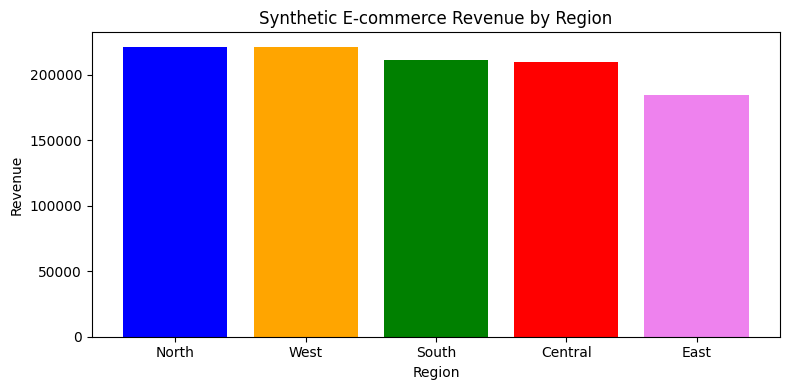

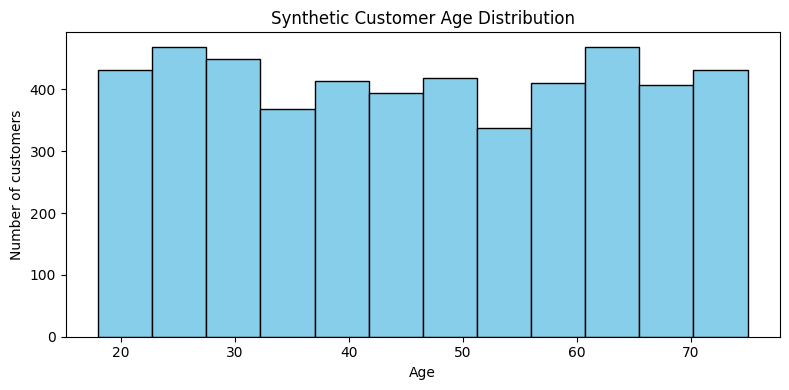

In [47]:
import seaborn as sns
colors = ["Blue", "Orange", "Green", "Red", "Violet"]

plt.figure(figsize=(8,4))
plt.bar(region_summary["region"], region_summary["revenue"], color=colors[:len(region_summary)])
plt.title("Synthetic E-commerce Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.hist(customers["age"], bins=12, color="skyblue", edgecolor="black")
plt.title("Synthetic Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

In [48]:
# Analyze popular_products and region_summary data
print("Summary of Regional E-commerce Revenue")
display(region_summary)

print("Top 10 Most Popular Products")
display(popular_products)

# Calculate basic metrics utilizing both datasets
total_revenue = region_summary["revenue"].sum()
top_products_revenue = popular_products["revenue"].sum()
share_percentage = (top_products_revenue / total_revenue) * 100

print(f"\nTotal Store Revenue: ${total_revenue:,.2f}")
print(f"Revenue from Top 10 Products: ${top_products_revenue:,.2f} ({share_percentage:.2f}% of total)")

Summary of Regional E-commerce Revenue


,region,number_of_orders,revenue
0,North,2599,221379.19
1,West,2506,221172.98
2,South,2408,211313.29
3,Central,2375,210125.64
4,East,2112,184556.84


Top 10 Most Popular Products


,product_name,category,units_sold,revenue
0,Product_057,Electronics,215,6591.22
1,Product_023,Electronics,211,6169.34
2,Product_168,Sports,207,7373.19
3,Product_056,Books,206,5703.97
4,Product_227,Clothing,200,4514.98
5,Product_094,Clothing,200,2050.71
6,Product_081,Electronics,200,8122.51
7,Product_066,Books,200,3210.31
8,Product_164,Home,199,2837.54
9,Product_112,Sports,197,2006.26



Total Store Revenue: $1,048,547.94
Revenue from Top 10 Products: $48,580.03 (4.63% of total)


## Export the SQLite database

In [49]:
conn.commit()
conn.close()

from google.colab import files
files.download(DB_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>